#  Phân cụm bài đăng dựa trên tương tác của người dùng Facebook Live tại Thái Lan (Facebook Live Seller in Thailand Engagement Clustering Analysis)

**Các phần chính:** 
1. Phân tích hành vi tương tác theo định dạng bài viết (`Photo`, `Video/Live`, `Status`, `Link`) và các khung giờ đăng bài, dựa trên 7050 bài đăng và 12 đặc trưng. 
2. Áp dụng thuật toán **K-Means Clustering** trên tập đặc trưng tương tác chuẩn hóa (áp dụng `StandardScaler` trên tập các đặc trưng `num_reactions`, `num_comments`, `num_shares`). Lựa chọn số cụm tối ưu (`k=3`) dựa trên **Elbow Method (WCSS)** và **Silhouette Score**. Ba cụm phân biệt  
gồm:
     - Cụm 0 (Standard / Low Engagement): Tương tác cơ bản, ít lượt comments và shares. Bài đăng chủ yếu dạng photo.
     - Cụm 1 (Viral / High Engagement): Lượt comments và shares cực cao (trung bình **3282,78** lượt comments và **507,37** lượt shares). Bài đăng chủ yếu dạng video/live.
     - Cụm 2 (Medium Engagement): Lượt likes và reactions cao nhưng comments/shares ở mức vừa. Bài đăng chủ yếu dạng photo và video.

Đặc biệt, **Cụm 1 (Viral / High Engagement)** tập trung ở giai đoạn trùng thời điểm Facebook ra mắt Live, có thể **Live Video** đã mang lại bước nhảy vọt về lượt tương tác nhờ độ sinh động, giúp người bán có thể kiểm soát và phản hồi ngay lập tức theo nhận xét của người xem theo thời gian thực, kết hợp đồng thời yếu tố giải trí, giao lưu xã hội và thông tin bán hàng.

**Công nghệ:** Python, pandas, numpy, scikit-learn, matplotlib, seaborn, ucimlrepo.

## A. Thiết lập Môi trường & Thu nạp Dữ liệu
Import các thư viện cần thiết:
- `pandas`, `numpy`: Xử lý và tính toán trên dữ liệu dạng bảng.
- `matplotlib`, `seaborn`: Trực quan hóa dữ liệu và biểu đồ phân tích.
- `scikit-learn`: Tiền xử lý (`StandardScaler`), phân cụm (`KMeans`), đánh giá mô hình (`silhouette_score`).
- `ucimlrepo`: Tải trực tiếp bộ dữ liệu chính thức từ UCI Machine Learning Repository (Dataset ID: 488).


In [1]:
%matplotlib inline
import warnings
warnings.simplefilter(action='ignore')

import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn import metrics

# Cấu hình thẩm mỹ cho biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

### Về bộ dữ liệu [Facebook Live Sellers in Thailand](https://archive.ics.uci.edu/dataset/488/facebook+live+sellers+in+thailand) từ UCI Machine Learning Repository (ID 488)

Bộ dữ liệu được giới thiệu trong bài báo [Dataset on usage and engagement patterns for Facebook Live sellers in Thailand](https://www.semanticscholar.org/paper/Dataset-on-usage-and-engagement-patterns-for-Live-Dehouche/c0ec91003f8bdce99a56fa60dc2d20268cc808b8) của tác giả **Nassim Dehouche** (2020). Bộ dữ liệu thu thập 7050 bài đăng thuộc nhiều loại khác nhau như trạng thái, đường dẫn, video quay sẵn (deferred video), video trực tiếp (live video) và hình ảnh trên Facebook của 10 nhà bán hàng thời trang và mỹ phẩm tại Thái Lan trong giai đoạn từ **tháng 3/2012 đến tháng 6/2018**.

Đối với mỗi bài đăng, bộ dữ liệu ghi lại các chỉ số tương tác bao gồm lượt chia sẻ, bình luận, phản ứng bằng biểu tượng cảm xúc (gồm like, love, wow, haha, sad và angry) và thời gian đăng tải.

Hai cột mốc đáng chú ý:
  * **Facebook Live (Livestream) ra mắt** chính thức trên toàn cầu, trong đó có cả Thái Lan **từ ngày 06/04/2016**. Trước mốc thời gian này, các người bán chủ yếu đăng video quay sẵn (deferred video). Trong bộ dữ liệu, sử dụng chung giá trị `video` cho cả video quay sẵn (deferred video) và video trực tiếp (live video). *Theo [Meta Newsroom, Reactions Now Available Globally](https://about.fb.com/news/2016/02/reactions-now-available-globally/)*
  
  * **Các biểu tượng cảm xúc mới trên Facebook (Love, Haha, Wow, Sad, Angry) ra mắt** chính thức cho toàn bộ người dùng trên toàn cầu **từ ngày 24/02/2016**. *Theo [The Indian Express, Facebook Launches Live Videos For Everyone](https://indianexpress.com/article/technology/tech-news-technology/facebook-launches-live-videos-for-everyone-rearranges-notification-panel-on-its-app/)*


In [2]:
# Tải dataset trực tiếp từ UCI Machine Learning Repository theo ID 488
facebook_live_sellers = fetch_ucirepo(id=488) 
# print(facebook_live_sellers.metadata)
# print(facebook_live_sellers.variables)

# Lấy toàn bộ dữ liệu dưới dạng Pandas DataFrame
df_raw = facebook_live_sellers.data.original.copy()

print(f"Kích thước dữ liệu ban đầu: {df_raw.shape[0]} dòng, {df_raw.shape[1]} cột")
df_raw.head()


Kích thước dữ liệu ban đầu: 7050 dòng, 12 cột


,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0


## B. Kiểm tra và Làm sạch dữ liệu

Trước khi tiến hành phân tích và áp dụng mô hình phân cụm, chúng ta thực hiện các bước kiểm tra chất lượng dữ liệu:
1. Kiểm tra kiểu dữ liệu của từng cột (dtypes).
2. Kiểm tra giá trị Null / Missing values.
3. Kiểm tra bản ghi trùng lặp (Duplicate Records) khi loại bỏ mã định danh `status_id`.
4. Kiểm tra tính nhất quán logic: `num_reactions == sum(num_likes + num_loves + num_wows + num_hahas + num_sads + num_angrys)`.
5. Trích xuất thuộc tính thời gian (`status_published` → `year`, `month`, `day`, `hour`, `day_of_week`).


### 1. Kiểm tra kiểu dữ liệu của từng cột (dtypes)

In [3]:
# Thông tin chung của dữ liệu: tổng số cột, giá trị null, kiểu dữ liệu (dtype) của từng cột
print("--- Thông tin cơ bản của dữ liệu ---")
df_raw.info()

--- Thông tin cơ bản của dữ liệu ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   status_id         7050 non-null   int64 
 1   status_type       7050 non-null   object
 2   status_published  7050 non-null   object
 3   num_reactions     7050 non-null   int64 
 4   num_comments      7050 non-null   int64 
 5   num_shares        7050 non-null   int64 
 6   num_likes         7050 non-null   int64 
 7   num_loves         7050 non-null   int64 
 8   num_wows          7050 non-null   int64 
 9   num_hahas         7050 non-null   int64 
 10  num_sads          7050 non-null   int64 
 11  num_angrys        7050 non-null   int64 
dtypes: int64(10), object(2)
memory usage: 661.1+ KB


In [4]:
# B.1. Kiểm tra kiểu dữ liệu của từng cột (dtypes)
print("--- Kiểu dữ liệu của mỗi cột ---")
df_raw.dtypes

--- Kiểu dữ liệu của mỗi cột ---


status_id            int64
status_type         object
status_published    object
num_reactions        int64
num_comments         int64
num_shares           int64
num_likes            int64
num_loves            int64
num_wows             int64
num_hahas            int64
num_sads             int64
num_angrys           int64
dtype: object

**Nhận xét:** 

* Kiểu dữ liệu (dtype) của 10/12 cột gồm `status_id`, `num_reactions`, `num_comments`, `num_shares`, `num_likes`, `num_loves`, `num_wows`, `num_hahas`, `num_sads`, `num_angrys` hợp lý khi là kiểu số nguyên (integer - int64). 
* Cột `status_type` (loại bài đăng gồm photo, video, link, status) là kiểu 'object'. → Có thể chuyển thành kiểu chuỗi 'string'.
* Cột `status_published` (thời gian xuất bản bài đăng) là kiểu 'object'. → Có thể chuyển thành kiểu thời gian (date time).


### 2. Kiểm tra giá trị Null / Missing values

In [5]:
# B.2. Kiểm tra Missing Values số nguyên 
print("--- Số lượng giá trị Null trên mỗi cột ---")
print(df_raw.isnull().sum())

--- Số lượng giá trị Null trên mỗi cột ---
status_id           0
status_type         0
status_published    0
num_reactions       0
num_comments        0
num_shares          0
num_likes           0
num_loves           0
num_wows            0
num_hahas           0
num_sads            0
num_angrys          0
dtype: int64


In [6]:
# Kiểm tra số lượng giá trị duy nhất (khác nhau) cho từng cột (hàm nunique())
print("--- Số lượng giá trị duy nhất (khác nhau) cho từng cột ---")
df_raw.nunique()

--- Số lượng giá trị duy nhất (khác nhau) cho từng cột ---


status_id           7050
status_type            4
status_published    6913
num_reactions       1067
num_comments         993
num_shares           501
num_likes           1044
num_loves            229
num_wows              65
num_hahas             42
num_sads              24
num_angrys            14
dtype: int64

**Nhận xét:** 

* Cột `status_id` có 7050 dữ liệu khác nhau. → Có vẻ như các dòng dữ liệu không bị trùng (có đúng không?)

* Cột `status_type` có 4 giá trị: photo, video, link, status (Theo bài báo giới thiệu [Dataset on usage and engagement patterns for Facebook Live sellers in Thailand](https://www.semanticscholar.org/paper/Dataset-on-usage-and-engagement-patterns-for-Live-Dehouche/c0ec91003f8bdce99a56fa60dc2d20268cc808b8))

* Cột `status_published` có 6913 dòng khác nhau, có vẻ như có 137 các bài đăng cùng 1 thời điểm.

### 3. Kiểm tra bản ghi trùng lặp (Duplicate Records) khi loại bỏ mã định danh `status_id`

Thử xoá cột `status_id` để kiểm tra dữ liệu có thật sự không trùng nhau

In [7]:
# 1. Bỏ cột status_id để tạo dataframe kiểm tra
df_no_id = df_raw.drop(columns=['status_id'])

In [8]:
# 2. Lấy ra tất cả các dòng bị trùng (bao gồm cả bản gốc và bản sao)
# Tham số keep=False sẽ đánh dấu tất cả các dòng trùng nhau (cả dòng gốc lẫn dòng nhân bản), dễ dàng so sánh chúng đặt cạnh nhau.

duplicate_records = df_no_id[df_no_id.duplicated(keep=False)]

print("Số lượng tất cả dòng trùng nhau (cả bản gốc và bản sao): ", duplicate_records.shape)

Số lượng tất cả dòng trùng nhau (cả bản gốc và bản sao):  (108, 11)


In [9]:
# 3. Sắp xếp theo thời gian và loại bài đăng để các dòng trùng nhau nằm sát nhau
duplicate_records_sorted = duplicate_records.sort_values(by=['status_published', 'status_type'])

# 4. Hiển thị thử 10 dòng đầu tiên để kiểm tra
print(f"Tổng số dòng liên quan đến trùng lặp: {len(duplicate_records_sorted)}")
duplicate_records_sorted.head(10)


Tổng số dòng liên quan đến trùng lặp: 108


,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
6220,photo,3/16/2018 1:57,985,71,42,962,5,16,2,0,0
6271,photo,3/16/2018 1:57,985,71,42,962,5,16,2,0,0
6219,photo,3/18/2018 4:28,1985,39,21,1961,11,12,0,1,0
6270,photo,3/18/2018 4:28,1985,39,21,1961,11,12,0,1,0
6218,photo,3/20/2018 1:54,186,15,1,172,3,11,0,0,0
6269,photo,3/20/2018 1:54,186,15,1,172,3,11,0,0,0
6217,photo,3/21/2018 1:15,114,6,1,108,3,3,0,0,0
6268,photo,3/21/2018 1:15,114,6,1,108,3,3,0,0,0
6216,photo,3/22/2018 3:48,879,165,18,867,4,8,0,0,0
6267,photo,3/22/2018 3:48,879,165,18,867,4,8,0,0,0


In [10]:
# B.3. Kiểm tra bản ghi trùng lặp (Duplicate Records)
# Cột status_id là mã định danh giả lập khiến các bài đăng trùng nội dung không bị phát hiện nếu giữ status_id
df_cleaned = df_raw.drop(columns=['status_id'])

duplicates_count = df_cleaned.duplicated().sum()
print(f"Số dòng dữ liệu bị trùng lặp phát hiện được: {duplicates_count}")

# Loại bỏ các dòng trùng lặp
df_cleaned = df_cleaned.drop_duplicates().reset_index(drop=True)
print(f"Kích thước dữ liệu sau khi loại bỏ duplicate: {df_cleaned.shape}")

Số dòng dữ liệu bị trùng lặp phát hiện được: 54
Kích thước dữ liệu sau khi loại bỏ duplicate: (6996, 11)


### 4. Kiểm tra tính nhất quán logic: `num_reactions == sum(num_likes + num_loves + num_wows + num_hahas + num_sads + num_angrys)`.

Kiểm tra tính hợp lý của cột `num_reactions`: 

Theo cấu trúc Facebook: num_reactions phải bằng tổng tất cả các cảm xúc con:
```ruby
num_reactions = num_likes + num_loves + num_wows + num_hahas + num_sads + num_angrys
```

Vậy dữ liệu có đúng như vậy?

In [11]:
# B.4. Kiểm tra tính nhất quán logic của các tương tác
# Thêm 1 cột calculated_reactions để tính tổng các num_likes, num_likes + num_loves + num_wows + num_hahas + num_sads + num_angrys

# Cú pháp cơ bản: df.iloc[<vị_trí_hàng>, <vị_trí_cột>]
# : = chọn tất cả các hàng
# 5:11 = cắt lát (slice) các cột theo vị trí chỉ số (index). Trong Python, vị trí cuối cùng (11) sẽ bị loại trừ. Do đó, hệ thống sẽ lấy các cột ở vị trí 5, 6, 7, 8, 9, 10

df_cleaned['calculated_reactions'] = df_cleaned.iloc[:,5:11].sum(axis=1)
df_cleaned.head(5)

,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,calculated_reactions
0,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,529
1,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,150
2,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,227
3,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,111
4,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,213


In [12]:
# Kiểm tra 2 cột calculated_reactions vừa tính và num_reactiums có giống nhau
df_cleaned['reaction_match'] = df_cleaned.apply(lambda x: x['num_reactions'] == x['calculated_reactions'],axis=1)
df_cleaned[['num_reactions','calculated_reactions','reaction_match']].head()

,num_reactions,calculated_reactions,reaction_match
0,529,529,True
1,150,150,True
2,227,227,True
3,111,111,True
4,213,213,True


In [13]:
# Liệt kê các trường hợp bằng False (num_reactions KHÔNG bằng tổng tất cả các cảm xúc con)
data_react_mismatch = df_cleaned[df_cleaned.reaction_match == False]

print("Số lượng bản ghi num_reactions != tổng cảm xúc con:", data_react_mismatch.shape)

Số lượng bản ghi num_reactions != tổng cảm xúc con: (9, 13)


**Nhận xét:**

Như vậy, có 9 dòng dữ liệu bị sai ở cột `num_reactions`. Bây giờ sẽ thay thế 9 `num_reactions` sai thành dữ liệu đúng.

In [14]:
df_cleaned.num_reactions = df_cleaned.calculated_reactions

# Chắc chắn rằng dữ liệu đã được thay thế đúng
df_cleaned['reaction_match'] = df_cleaned.apply(lambda x: x['num_reactions'] == x['calculated_reactions'],axis=1)
df_cleaned[df_cleaned.reaction_match == True].shape

(6996, 13)

In [15]:
# Sau khi kiểm tra, xoá 2 cột calculated_reactions và reaction_match
df_cleaned = df_cleaned.drop(['calculated_reactions'], axis='columns')
df_cleaned = df_cleaned.drop(['reaction_match'], axis='columns')
print("Hoàn tất kiểm tra tính logic, kích thước của dữ liệu là: ",df_cleaned.shape)

Hoàn tất kiểm tra tính logic, kích thước của dữ liệu là:  (6996, 11)


### 5. Trích xuất thuộc tính thời gian (`status_published` -> `year`, `month`, `day`, `hour`, `day_of_week`).

In [16]:
# B.5. Xử lý & Trích xuất thuộc tính thời gian
# Chuyển cột status_published thành kiểu datetime
df_cleaned['status_published'] = pd.to_datetime(df_cleaned['status_published'])

# Tạo 5 cột mới là: year, month, day, hour, day_of_week
df_cleaned['year'] = df_cleaned['status_published'].dt.year
df_cleaned['month'] = df_cleaned['status_published'].dt.month
df_cleaned['day'] = df_cleaned['status_published'].dt.day
df_cleaned['hour'] = df_cleaned['status_published'].dt.hour
df_cleaned['day_of_week'] = df_cleaned['status_published'].dt.day_name()

df_cleaned.head(3)


,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,year,month,day,hour,day_of_week
0,video,2018-04-22 06:00:00,529,512,262,432,92,3,1,1,0,2018,4,22,6,Sunday
1,photo,2018-04-21 22:45:00,150,0,0,150,0,0,0,0,0,2018,4,21,22,Saturday
2,video,2018-04-21 06:17:00,227,236,57,204,21,1,1,0,0,2018,4,21,6,Saturday


## C. Phân tích Khám phá Dữ liệu (EDA)

Trong phần này sẽ phân tích các khía cạnh chính của tương tác:
1. **Phân bổ loại bài đăng**: Người bán ưu tiên hình thức nào?
2. **Khung giờ đăng bài**: Thời điểm nào trong ngày tập trung nhiều bài đăng và tương tác cao nhất? Bài đăng vào thứ nào trong tuần có nhiều tương tác? Phân bố bài đăng theo năm như thế nào?
3. **Mối tương quan tương tác**: Mối quan hệ giữa Like, Comment, Share và các cảm xúc khác.

### 1. Phân bố Loại bài đăng

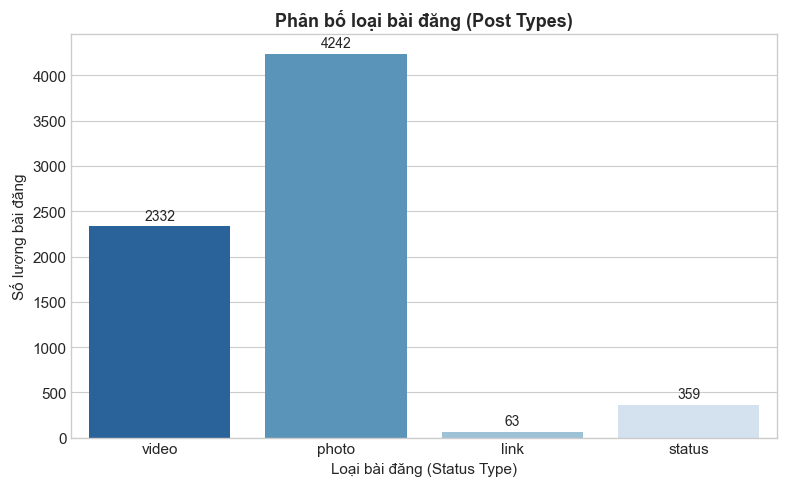

In [17]:
# C.1. Sự phân bố loại bài đăng (status_type)
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df_cleaned, x="status_type", palette= 'Blues_r')
ax.set_title('Phân bố loại bài đăng (Post Types)', fontsize=13, fontweight='bold')
ax.set_xlabel('Loại bài đăng (Status Type)')
ax.set_ylabel('Số lượng bài đăng')

# Chú thích số lượng cụ thể trên đỉnh mỗi cột
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

**Nhận xét:** 

* Các bài đăng nhiều nhất dưới dạng `photo` (4242/6996 bài đăng). Sau đó đến `video` (2332/6996 bài đăng).

* Các bài đăng dạng `status` và `link` là ít nhất. Có thể lý giải vì hai loại bài đăng này ít sinh động, dễ bỏ qua và thường không đạt hiệu quả quảng bá.

### 2. Phân bố Bài đăng & Mức độ Tương tác theo Giờ trong Ngày

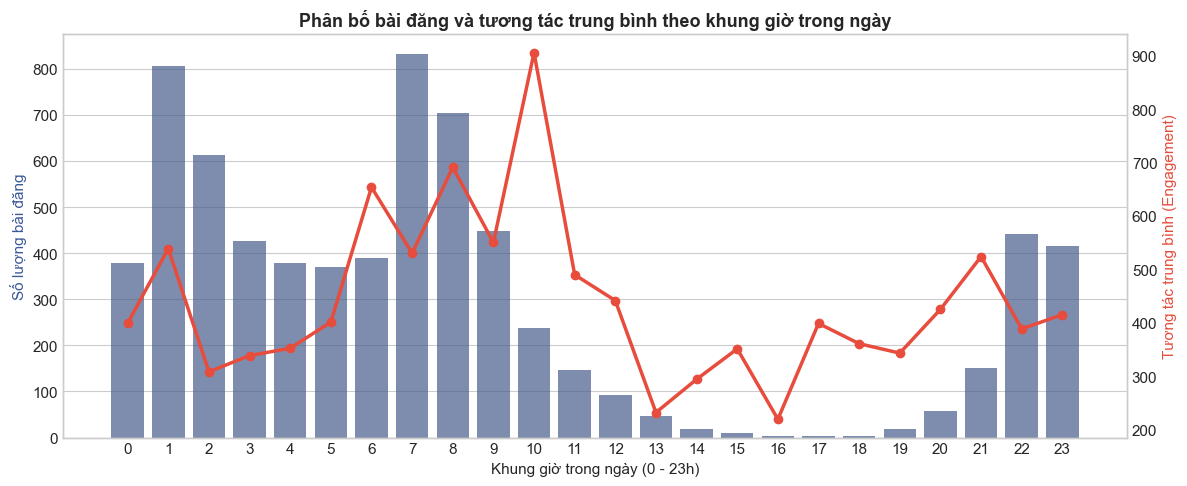

In [18]:
# C.2. Khung giờ đăng bài và mức độ tương tác theo giờ
fig, ax1 = plt.subplots(figsize=(12, 5))

# Số lượng bài đăng theo giờ
sns.countplot(data=df_cleaned, x='hour', color='#3b5998', alpha=0.7, ax=ax1)
ax1.set_title('Phân bố bài đăng và tương tác trung bình theo khung giờ trong ngày', fontsize=13, fontweight='bold')
ax1.set_xlabel('Khung giờ trong ngày (0 - 23h)')
ax1.set_ylabel('Số lượng bài đăng', color='#3b5998')

# Đường tương tác trung bình (Reactions + Comments + Shares)
avg_engagement = df_cleaned.groupby('hour')[['num_reactions', 'num_comments', 'num_shares']].mean().sum(axis=1)
ax2 = ax1.twinx()
ax2.plot(avg_engagement.index, avg_engagement.values, color='#e74c3c', marker='o', linewidth=2.5, label='Avg Total Engagement')
ax2.set_ylabel('Tương tác trung bình (Engagement)', color='#e74c3c')
ax2.grid(False)

plt.tight_layout()
plt.show()

**Nhận xét:** 

* Các bài đăng được đăng tải nhiều nhất vào tầm sáng (7-8 giờ sáng) và lúc đêm khuya (1-2 giờ sáng).
* Khoảng từ 10 giờ đến 21 giờ, rất ít bài đăng, nhưng lượng tương tác trung bình lại khá cao (khoảng 10 giờ đến 12 giờ).

### 3. Phân bố Bài đăng & Mức độ Tương tác theo Thứ trong Tuần

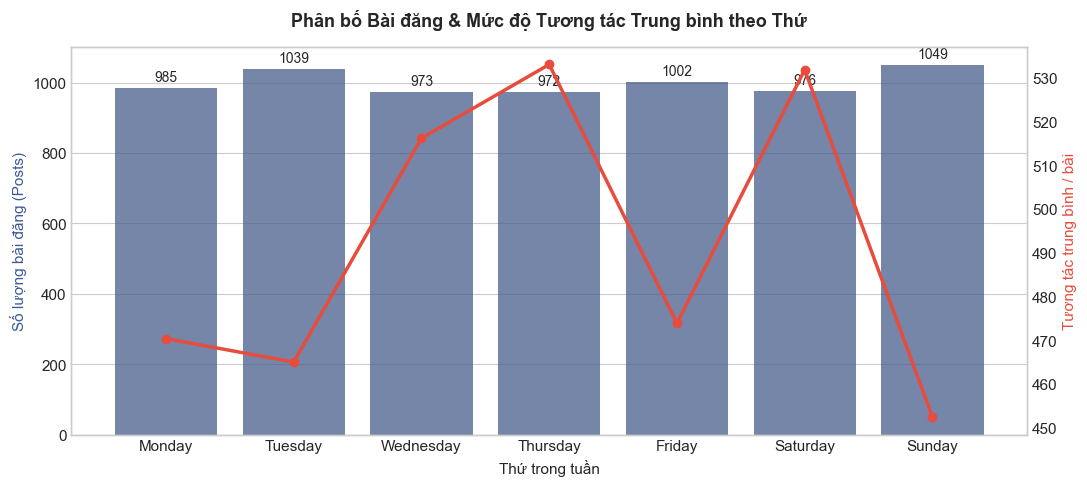

In [19]:
# Lượng bài đăng & mức độ tương tác theo Thứ trong tuần 
# Định nghĩa thứ tự từ Thứ 2 -> Chủ Nhật
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

fig, ax1 = plt.subplots(figsize=(11, 5))

# Cột: Số lượng bài đăng theo Thứ
sns.countplot(data=df_cleaned, x='day_of_week', order=days_order, color='#3b5998', alpha=0.75, ax=ax1)
ax1.set_title('Phân bố Bài đăng & Mức độ Tương tác Trung bình theo Thứ', fontsize=13, fontweight='bold', pad=15)
ax1.set_xlabel('Thứ trong tuần', fontsize=11)
ax1.set_ylabel('Số lượng bài đăng (Posts)', color='#3b5998', fontsize=11)
# Chú thích số lượng cụ thể trên đỉnh mỗi cột
for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, 
                xytext=(0, 5), textcoords='offset points')

# Đường: Tương tác trung bình (Reactions + Comments + Shares)
# Tính toán lượng tương tác trung bình theo từng thứ
avg_engagement_day = df_cleaned.groupby('day_of_week')[['num_reactions', 'num_comments', 'num_shares']].mean().sum(axis=1).reindex(days_order)
ax2 = ax1.twinx()
ax2.plot(range(len(days_order)), avg_engagement_day.values, color='#e74c3c', marker='o', linewidth=2.5, label='Avg Engagement')
ax2.set_ylabel('Tương tác trung bình / bài', color='#e74c3c', fontsize=11)
ax2.grid(False)

plt.tight_layout()
plt.show()


**Nhận xét:** 

* Các bài đăng được đăng tải vào tất cả các ngày trong tuần.
* Lượng tương tác trung bình cao hơn vào các ngày thứ 4, thứ 5 và thứ 7. 

### 4. Phân bố Bài đăng theo Năm

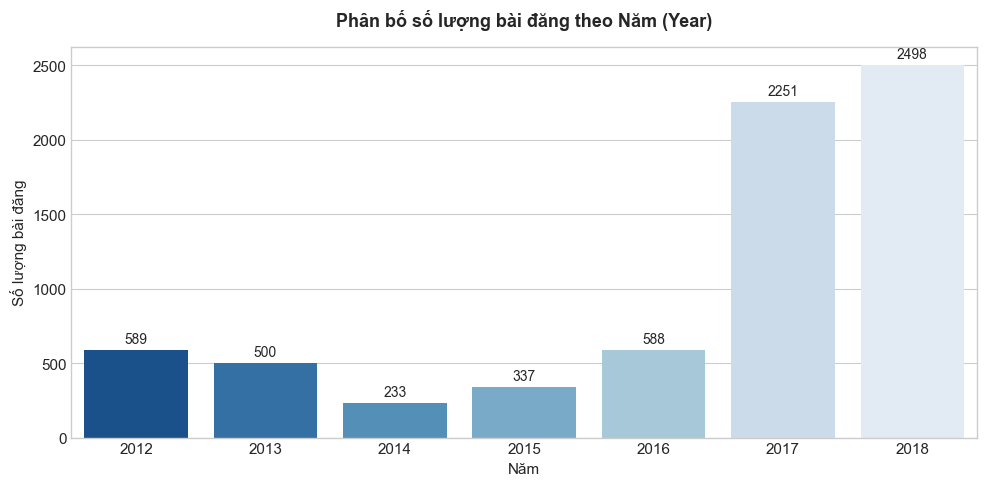

In [20]:
# Phân bố các bài đăng dựa trên năm (year)
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=df_cleaned, x='year', palette='Blues_r')
plt.title('Phân bố số lượng bài đăng theo Năm (Year)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Năm', fontsize=11)
plt.ylabel('Số lượng bài đăng', fontsize=11)

# Chú thích số lượng cụ thể trên đỉnh mỗi cột
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, 
                xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()

**Nhận xét:** 

* Theo bài báo giới thiệu, dữ liệu được thu thập trong giai đoạn từ **tháng 3/2012 đến tháng 6/2018**. Nhưng số lượng bài đăng năm **2017** và **2018** chiếm nhiều hơn cả.

### 5. Ma trận Tương quan giữa các Chỉ số Tương tác

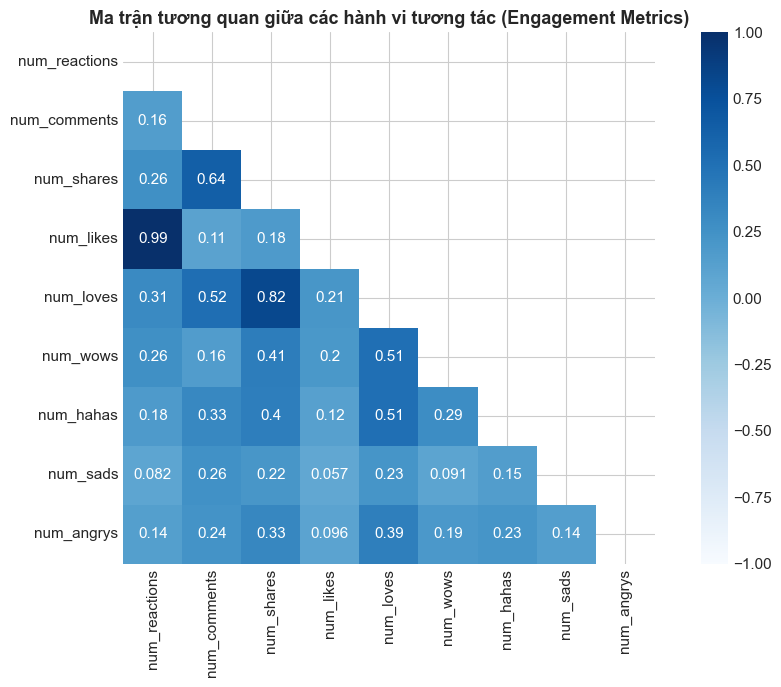

In [21]:
# C.3. Ma trận tương quan giữa các chỉ số tương tác (Correlation Matrix)
interaction_cols = ['num_reactions', 'num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']

plt.figure(figsize=(10,7))
corr_matrix= df_cleaned[interaction_cols].corr()

mask = np.zeros_like(corr_matrix)
mask[np.triu_indices_from(mask)] = True
 
sns.heatmap(corr_matrix,mask=mask,cmap="Blues",annot=True, vmin=-1, vmax=1,square=True)

plt.title('Ma trận tương quan giữa các hành vi tương tác (Engagement Metrics)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

**Nhận xét:** Heat map thể hiện sự tương quan giữa các đặc trưng, hệ số càng cao tương quan càng lớn.
* **num_reactions với num_likes (0.99)**: Nút like đã xuất hiện từ đầu, trước khi Facebook thêm các reactions khác, nên tổng tương tác (num_reactions) tương quan rất cao với lượt like (num_likes).
* **num_comments với num_shares (0.64)**: Có vẻ như nếu đã comment vào một bài đăng, rất có thể người dùng Facebook muốn chia sẻ nó với người khác.
* **num_shares với num_loves và num_comments với num_loves (0.82 và 0.52)**: Thể hiện rằng bài viết tạo ra **cảm xúc tích cực mạnh** sẽ kích thích người xem thảo luận và chia sẻ nhiều hơn.

## D. Xây dựng Đặc trưng & Chuẩn hóa Dữ liệu

### Lý do cần Chuẩn hóa Dữ liệu trước khi áp dụng K-Means
Thuật toán **K-Means sử dụng khoảng cách Euclidean** để đo độ tương đồng giữa các điểm dữ liệu. 
- Nếu không chuẩn hóa, một thuộc tính có biên độ giá trị lớn (như `num_reactions` lên đến hàng ngàn) sẽ **áp đảo hoàn toàn** các thuộc tính có biên độ nhỏ (như `num_comments`, `num_shares` chỉ vài chục, vài trăm), dẫn đến kết quả phân cụm bị sai lệch.
- Ta áp dụng `StandardScaler` để đưa tất cả các đặc trưng về phân phối chuẩn có $\mu = 0$ và $\sigma = 1$.


In [22]:
# Lựa chọn tập thuộc tính hành vi tương tác để đưa vào mô hình phân cụm
feature_cols = ['num_reactions', 'num_comments', 'num_shares']

X = df_cleaned[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Dữ liệu sau khi chuẩn hóa (X_scaled): Shape = {X_scaled.shape}")
pd.DataFrame(X_scaled, columns=feature_cols).head(3)

Dữ liệu sau khi chuẩn hóa (X_scaled): Shape = (6996, 3)


,num_reactions,num_comments,num_shares
0,0.671005,0.320713,1.678925
1,-0.165787,-0.252726,-0.304974
2,0.004221,0.011593,0.126637


## E. Phân cụm K-Means & Đánh giá mô hình

Để xác định số lượng cụm $k$ tối ưu nhất, ta sử dụng kết hợp 2 phương pháp:
1. **Phương pháp Elbow (Phương pháp khuỷu tay)**: Quan sát điểm gãy của đồ thị giữa số lượng cụm $K$ và Inertia, điểm gãy có thể là số lượng cụm $K$ tối ưu. 
2. **Phân tích Hệ số Silhouette (Silhouette Score)**: Đánh giá độ tách biệt giữa các cụm và độ gắn kết nội bộ từng cụm ($s \in [-1, 1]$).

Tài liệu tham khảo:

[1] P. J. Rousseeuw, ["Silhouettes: A graphical aid to the interpretation and validation of cluster analysis"](https://wis.kuleuven.be/stat/robust/papers/publications-1987/rousseeuw-silhouettes-jcam-sciencedirectopenarchiv.pdf), *Journal of Computational and Applied Mathematics*, vol. 20, pp. 53–65, 1987.


[2] L. Kaufman and P. J. Rousseeuw, [*Finding Groups in Data: An Introduction to Cluster Analysis*](https://www.researchgate.net/publication/5142763_Clustering_in_an_Object-Oriented_Environment), John Wiley & Sons, 1990.

[3] GeeksforGeeks, [*What is Silhouette Score*](https://www.geeksforgeeks.org/machine-learning/what-is-silhouette-score/), 2026.

[4] GeeksforGeeks, [*Elbow Method for optimal value of k in KMeans*](https://www.geeksforgeeks.org/machine-learning/elbow-method-for-optimal-value-of-k-in-kmeans/), 2026.

---

<span style="color: coral">Elbow Method:</span> là một phương pháp trực quan giúp xác định số lượng cụm ($K$) phù hợp trong thuật toán phân cụm K-Means.

**Một số khái niệm:**

WCSS (Within-Cluster Sum of Squares) / Inertia: Đo tổng bình phương khoảng cách giữa các điểm dữ liệu và tâm cụm gần nhất.

Elbow Point: Tại một giá trị $K$ nào đó, tốc độ giảm của WCSS / Inertia sẽ chậm lại đột ngột và tạo thành một góc gãy giống như hình khuỷu tay trên đồ thị. Điểm khuỷu tay này có thể là số lượng cụm $K$ tối ưu.

**Các bước thực hiện Elbow Method:**

Bước 1: Chọn một phạm vi giá trị $K$

Bước 2: Chạy K-Means với từng giá trị $K$. Mỗi lần chạy, tính Inertia tương ứng với mỗi giá trị K.

Bước 3: Vẽ biểu đồ
- Trục X: Số lượng cụm $K$
- Trục Y: Giá trị Inertia

Bước 4: Xác định Elbow Point, là cơ sở để lựa chọn số cụm $K$ phù hợp.

![Biểu đồ Elbow Method](https://media.geeksforgeeks.org/wp-content/uploads/20251111115104211390/elbow_method.webp)

**Cách lựa chọn $K$:**

Khi tăng số lượng cụm, Inertia thường giảm (do tăng $K$ tạo thêm tâm cụm, giúp giảm khoảng cách từ điểm dữ liệu đến tâm gần nhất). Tuy nhiên, mức độ cải thiện sẽ giảm dần sau một ngưỡng nhất định. Điểm chuyển tiếp này được gọi là Elbow Point (điểm khuỷu tay) và là cơ sở để lựa chọn số cụm $K$ phù hợp.

> Lưu ý: Elbow Method mang tính chất tham khảo; không phải bộ dữ liệu nào cũng có điểm khuỷu tay rõ ràng.

---

<span style="color: coral">Silhouette Score: </span> chỉ số để đánh giá chất lượng phân cụm được giới thiệu bởi Rousseeuw (1987), đo lường mức độ tương đồng của một điểm dữ liệu đối với cụm của chính nó (độ gắn kết) so với các cụm khác (độ phân tách). Kết quả được đối chiếu với các ngưỡng diễn giải định tính của Kaufman và Rousseeuw (1990).

Với mỗi điểm dữ liệu $i$, điểm Silhouette $s(i)$ được tính theo công thức:

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

Trong đó:
*   **$a(i)$ (Cohesion - Độ gắn kết):** Khoảng cách trung bình từ điểm $i$ đến tất cả các điểm khác trong *cùng một cụm*. Giá trị này càng **nhỏ** càng tốt (thể hiện cụm đặc).
*   **$b(i)$ (Separation - Độ phân tách):** Khoảng cách trung bình từ điểm $i$ đến tất cả các điểm thuộc *cụm lân cận gần nhất*. Giá trị này càng **lớn** càng tốt (thể hiện các cụm tách biệt nhau).

**Average Silhouette Score** của mô hình là giá trị trung bình cộng của $s(i)$ của toàn bộ các điểm dữ liệu trong tập dữ liệu.

$$\overline{s}=\frac{1}{n}\sum _{i=1}^{n}s(i)$$

Giá trị của Silhouette Score luôn nằm trong khoảng từ **$-1$ đến $+1$**:

*   **$s(i) \approx +1$:** Cụm rất gọn gàng và tách biệt tốt.
*   **$s(i) \approx 0$:** Điểm dữ liệu nằm ở ranh giới giao thoa giữa các cụm.
*   **$s(i) \approx -1$:** Điểm dữ liệu có khả năng cao đã bị phân sai cụm (nó gần các điểm ở cụm khác hơn cụm hiện tại).

Ngưỡng diễn giải định tính (subjective interpretation heuristics) của Kaufman và Rousseeuw (1990) dựa trên thực nghiệm phong phú và độc lập với số lượng điểm dữ liệu:
*   **0.71 - 1.00:** Các cụm phân tách rất tốt và rõ ràng.
*   **0.51 - 0.70:** Cấu trúc phân cụm ở mức tốt, chấp nhận được.
*   **0.26 - 0.50:** Các cụm bị chồng chéo nhiều, cấu trúc yếu.
*   **< 0.26:** Phân cụm không hiệu quả (chọn sai số cụm $K$ hoặc đặc trưng dữ liệu không phù hợp).

> Chọn giá trị $K$ có **Silhouette Score Average cao nhất**, đồng thời đảm bảo số lượng điểm có Silhouette score bị âm là ít nhất.

---

### 1. Xác định Số cụm K tối ưu bằng Phương pháp Elbow

In [23]:
def optimise_k_means_elbow_method (data, max_k):
    # Tạo danh sách các giá trị k muốn thử nghiệm
    k_values = list(range(2, max_k))
    inertias = []

    for k in k_values:
        kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
        # Chỉ cần fit(data) là đủ để lấy inertia, giúp tối ưu tốc độ hơn
        kmeans_model.fit(data) 

        inertias.append(kmeans_model.inertia_)
        print(f"k = {k} | WCSS (Inertia) = {kmeans_model.inertia_:10.2f}")

    # Vẽ đồ thị elbow plot
    plt.subplots(figsize=(10, 5))
    plt.plot(k_values, inertias,'o-')
    plt.xlabel('Số lượng cụm k')
    plt.ylabel ('Inertia (WCSS)')
    plt.title('Elbow Method (WCSS vs K)')
    plt.grid (True)
    plt.show()

k = 2 | WCSS (Inertia) =   12900.46
k = 3 | WCSS (Inertia) =    8142.06
k = 4 | WCSS (Inertia) =    6210.37
k = 5 | WCSS (Inertia) =    5054.97
k = 6 | WCSS (Inertia) =    4275.62
k = 7 | WCSS (Inertia) =    3626.15
k = 8 | WCSS (Inertia) =    3048.63
k = 9 | WCSS (Inertia) =    2602.46


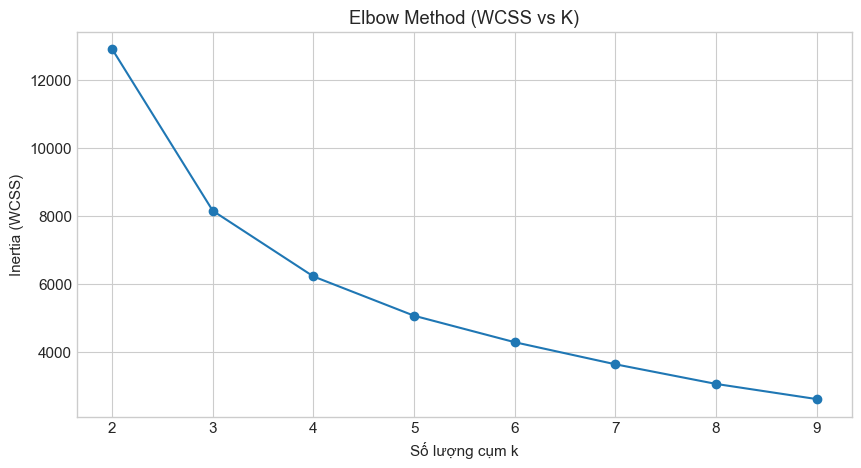

In [24]:
# Tìm k bằng elbow, với dữ liệu X_scaled
optimise_k_means_elbow_method (X_scaled, 10)

### 2. Xác định Số cụm K tối ưu bằng Hệ số Silhouette

In [25]:
def optimise_k_means_silhouette_score_method (data, max_k):
    # Tạo danh sách các giá trị k muốn thử nghiệm
    k_values = list(range(2, max_k))
    silhouette_scores = []

    for k in k_values:
        kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
        cluster_labels = kmeans_model.fit_predict(data)

        sil_score = metrics.silhouette_score(data, cluster_labels)
        silhouette_scores.append(sil_score)
        print(f"k = {k} | Silhouette Score = {sil_score:.4f}")

    # Vẽ đồ thị silhouette score plot
    plt.subplots(figsize=(10, 5))
    plt.plot(k_values, silhouette_scores,'o-')
    plt.xlabel('Số lượng cụm k')
    plt.ylabel ('Inertia')
    plt.title('Silhouette Score')
    plt.grid (True)
    plt.show()

k = 2 | Silhouette Score = 0.8170
k = 3 | Silhouette Score = 0.7969
k = 4 | Silhouette Score = 0.7920
k = 5 | Silhouette Score = 0.7631
k = 6 | Silhouette Score = 0.7589
k = 7 | Silhouette Score = 0.7555
k = 8 | Silhouette Score = 0.7541
k = 9 | Silhouette Score = 0.7560


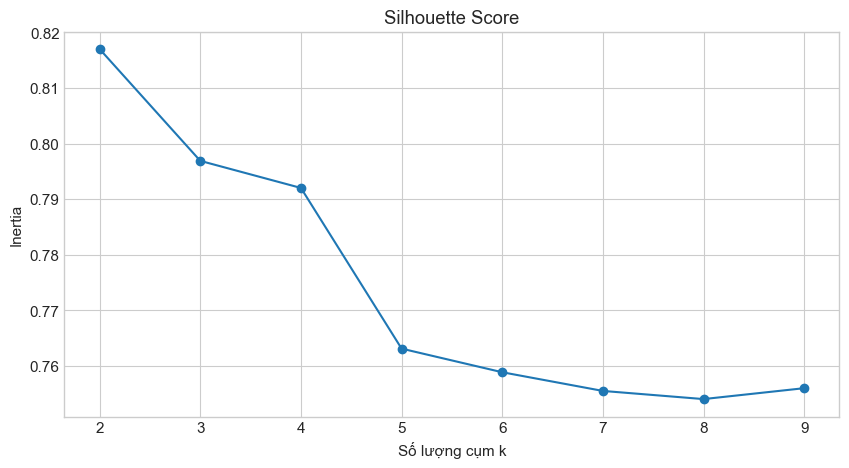

In [26]:
# Tìm k bằng silhouette score, với dữ liệu X_scaled
optimise_k_means_silhouette_score_method (X_scaled, 10)

**Lựa chọn số cụm $k$ tối ưu:**

- **$k=3$ hoặc $k=4$** tạo ra điểm gập rõ ràng trên đường Elbow và duy trì Silhouette Score ở mức cao (> 0.70).
- Nếu phân nhóm bài đăng theo mức độ hiệu quả, cụm bài đăng nào có mức tương tác thấp, trung bình và cao, **$k=3$** cung cấp sự phân tách rõ ràng và dễ hành động nhất giữa 3 nhóm: **Viral/High Engagement**, **Medium Engagement**, và **Low/Standard Engagement**.

### 3. Huấn luyện Mô hình K-Means với k=3

In [27]:
# E.3. Huấn luyện mô hình K-Means với k=3
OPTIMAL_K = 3
kmeans_final = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
df_cleaned['cluster'] = kmeans_final.fit_predict(X_scaled)

df_cleaned['total_engagement'] = (df_cleaned['num_reactions'] + df_cleaned['num_comments'] + df_cleaned['num_shares'])

cluster_summary = pd.DataFrame({
    'Số lượng': df_cleaned['cluster'].value_counts(),
    'Tỷ lệ (%)': (df_cleaned['cluster'].value_counts(normalize=True) * 100).round(2),
    'Median tương tác': df_cleaned.groupby('cluster')['total_engagement'].median().round(2),
    'Mean tương tác': df_cleaned.groupby('cluster')['total_engagement'].mean().round(2)
}).sort_index()

print("Phân bổ số lượng, median tương tác, mean tương tác và tỷ lệ bài đăng theo từng cụm:")
print(cluster_summary)

Phân bổ số lượng, median tương tác, mean tương tác và tỷ lệ bài đăng theo từng cụm:
         Số lượng  Tỷ lệ (%)  Median tương tác  Mean tương tác
cluster                                                       
0            6306      90.14              50.0          215.21
1             305       4.36            3775.0         4485.51
2             385       5.50            1834.0         1843.91


**Nhận xét** 

Sau khi chạy K-Means với $k=3$, ta có 3 cụm với sự phân bổ bài đăng và mức tương tác (reactions, comments, shares) có khác biệt rõ rệt.
- Cụm 0 có số bài đăng cao nhất (6306/6996) nhưng mức tương tác thấp nhất.
- Cụm 1 và Cụm 2 có số bài đăng xấp xỉ nhau nhưng mức tương tác Cụm 1 gấp 2 lần Cụm 2.

## F. Phân tích Chân dung Cụm

Để chuyển đổi kết quả phân cụm thành giá trị thực tiễn, ta phân tích chân dung cụm thông qua giá trị trung bình của các chỉ số tương tác, định dạng bài đăng và mốc thời gian ra mắt Facebook Live toàn cầu **06/04/2016**.

1. **Giá trị trung bình của các chỉ số tương tác**: Dùng Heatmap tâm cụm (Cluster Centroid Heatmap) hiển thị màu theo giá trị trung bình chuẩn hóa (standardized mean) và chú thích bằng số liệu thực tế của các tương tác theo từng cụm.

2. **Định dạng bài đăng trước và sau khi Facebook Live ra mắt**: Tỷ lệ 4 loại bài đăng trong từng cụm và sự tăng trưởng mạnh của định dạng bài đăng `video` trùng thời điểm Facebook Live ra mắt.

### 1. Phân tích Chân dung Cụm qua Giá trị trung bình các Chỉ số Tương tác

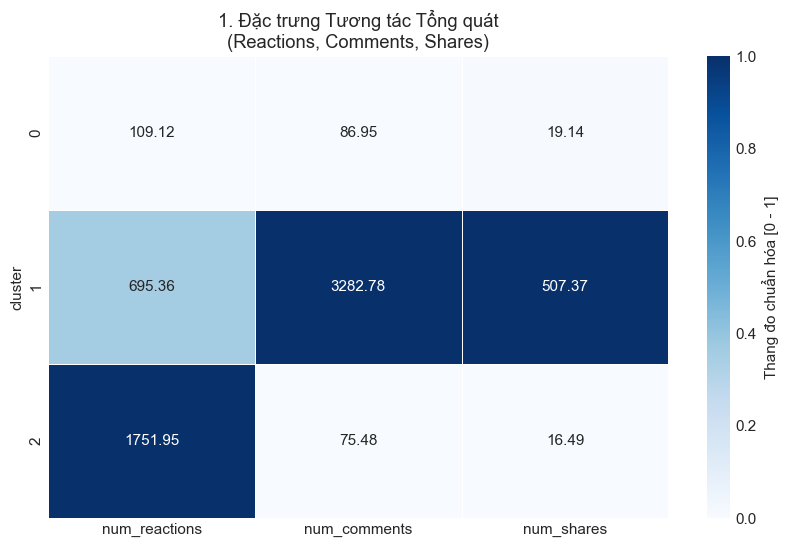

In [28]:
# F.1. Cluster Profile - Heatmap 1: Đặc trưng tương tác chính (Reactions, Comments, Shares)
cluster_profiles = df_cleaned.groupby('cluster')[['num_reactions', 'num_comments', 'num_shares']].mean()

# Chuẩn hóa min-max để hiển thị thang đo đồng đều trên heatmap
cluster_profiles_norm = (cluster_profiles - cluster_profiles.min()) / (cluster_profiles.max() - cluster_profiles.min())

sns.heatmap(cluster_profiles_norm, annot=cluster_profiles, cmap="Blues", fmt=".2f", linewidths=0.5, vmin=0, vmax=1, cbar_kws={'label': 'Thang đo chuẩn hóa [0 - 1]'})
plt.title("1. Đặc trưng Tương tác Tổng quát\n(Reactions, Comments, Shares)")
plt.show()

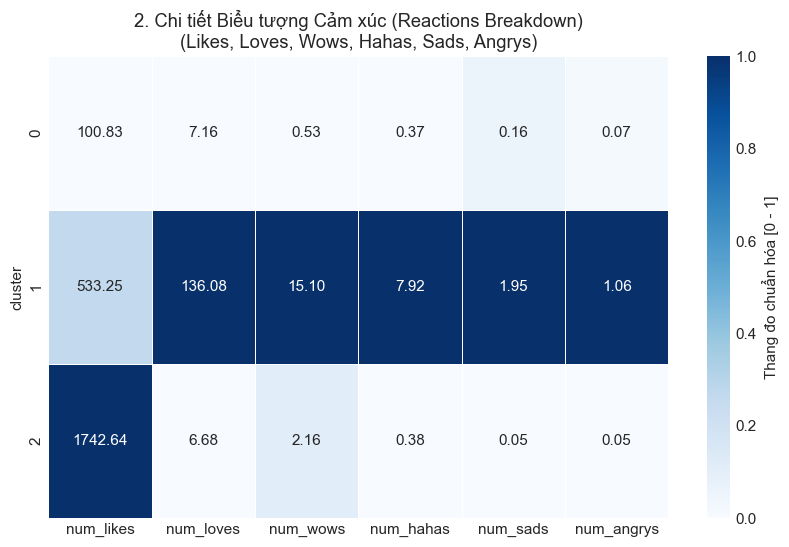

In [29]:
# F.2. Cluster Profile - Heatmap 2: Chi tiết các biểu tượng cảm xúc (Likes, Loves, Wows, Hahas, Sads, Angrys)
reactions_profiles = df_cleaned.groupby('cluster')[['num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']].mean()

# Chuẩn hóa min-max để hiển thị thang đo đồng đều trên heatmap
reactions_profiles_norm = (reactions_profiles - reactions_profiles.min()) / (reactions_profiles.max() - reactions_profiles.min())

sns.heatmap(reactions_profiles_norm, annot=reactions_profiles, cmap="Blues", fmt=".2f", linewidths=0.5, vmin=0, vmax=1, cbar_kws={'label': 'Thang đo chuẩn hóa [0 - 1]'})
plt.title("2. Chi tiết Biểu tượng Cảm xúc (Reactions Breakdown)\n(Likes, Loves, Wows, Hahas, Sads, Angrys)")
plt.show()

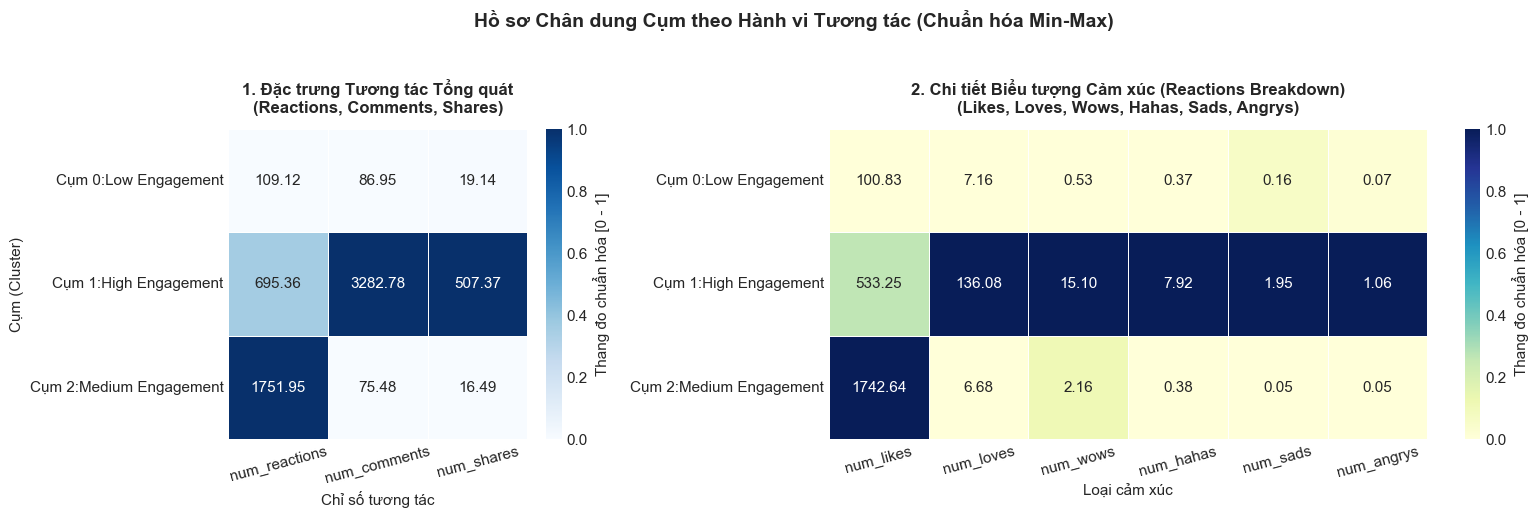

In [30]:
# F.1 & F.2: Cluster Profiling - 2 Heatmap cạnh nhau thể hiện chân dung cụm
# 1. Định nghĩa 2 nhóm thuộc tính
eng_cols = ['num_reactions', 'num_comments', 'num_shares']
react_cols = ['num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']

# 2. Tính giá trị đại diện theo cụm (dùng .mean() theo tâm K-Means, hoặc đổi thành .median() khi muốn tránh nhiễu do các bài đăng viral đột biến (outliers))
eng_profile = df_cleaned.groupby('cluster')[eng_cols].mean()
react_profile = df_cleaned.groupby('cluster')[react_cols].mean()

# 3. Chuẩn hóa Min-Max theo từng cột để đưa về thang đo [0, 1]
eng_norm = (eng_profile - eng_profile.min()) / (eng_profile.max() - eng_profile.min())
react_norm = (react_profile - react_profile.min()) / (react_profile.max() - react_profile.min())

# 4. Đặt nhãn gợi nhớ cho các cụm trên trục Y (giúp biểu đồ dễ đọc hơn)
cluster_labels = ['Cụm 0:Low Engagement', 'Cụm 1:High Engagement', 'Cụm 2:Medium Engagement']
eng_norm.index = cluster_labels
react_norm.index = cluster_labels

# 5. Khởi tạo khung vẽ 1 hàng 2 cột với tỷ lệ bề rộng 3:6 (tương ứng số cột 3 và 6)
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [3, 6]})

# --- Heatmap 1: Đặc trưng tương tác chính ---
sns.heatmap(
    eng_norm, 
    annot=eng_profile, 
    cmap='Blues', 
    fmt='.2f', 
    linewidths=0.5, 
    vmin=0, 
    vmax=1, 
    cbar_kws={'label': 'Thang đo chuẩn hóa [0 - 1]'},
    ax=axes[0]
)
axes[0].set_title('1. Đặc trưng Tương tác Tổng quát\n(Reactions, Comments, Shares)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel('Cụm (Cluster)', fontsize=11)
axes[0].set_xlabel('Chỉ số tương tác', fontsize=11)
axes[0].tick_params(axis='x', rotation=15)

# --- Heatmap 2: Chi tiết các biểu tượng cảm xúc ---
sns.heatmap(
    react_norm, 
    annot=react_profile, 
    cmap='YlGnBu', 
    fmt='.2f', 
    linewidths=0.5, 
    vmin=0, 
    vmax=1, 
    cbar_kws={'label': 'Thang đo chuẩn hóa [0 - 1]'},
    ax=axes[1]
)
axes[1].set_title('2. Chi tiết Biểu tượng Cảm xúc (Reactions Breakdown)\n(Likes, Loves, Wows, Hahas, Sads, Angrys)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_ylabel('') # Ẩn nhãn Y ở biểu đồ thứ 2 để tránh trùng lặp
axes[1].set_xlabel('Loại cảm xúc', fontsize=11)
axes[1].tick_params(axis='x', rotation=15)

plt.suptitle('Hồ sơ Chân dung Cụm theo Hành vi Tương tác (Chuẩn hóa Min-Max)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Nhận xét** 

Dựa trên Heatmap tâm cụm, ta thấy:
* **Cụm 1** đặc trưng bởi **Comment và Share** rất cao, trung bình **3282,78** lượt comments và **507,37** lượt shares. → Cụm **Viral/High Engagement**
* **Cụm 2** có lượt **Reactions và Likes** cao nhưng comments/shares ở mức vừa. → Cụm **Medium Engagement**
* **Cụm 0** có lượng tương tác không nổi bật. → Cụm **Low/Standard Engagement**

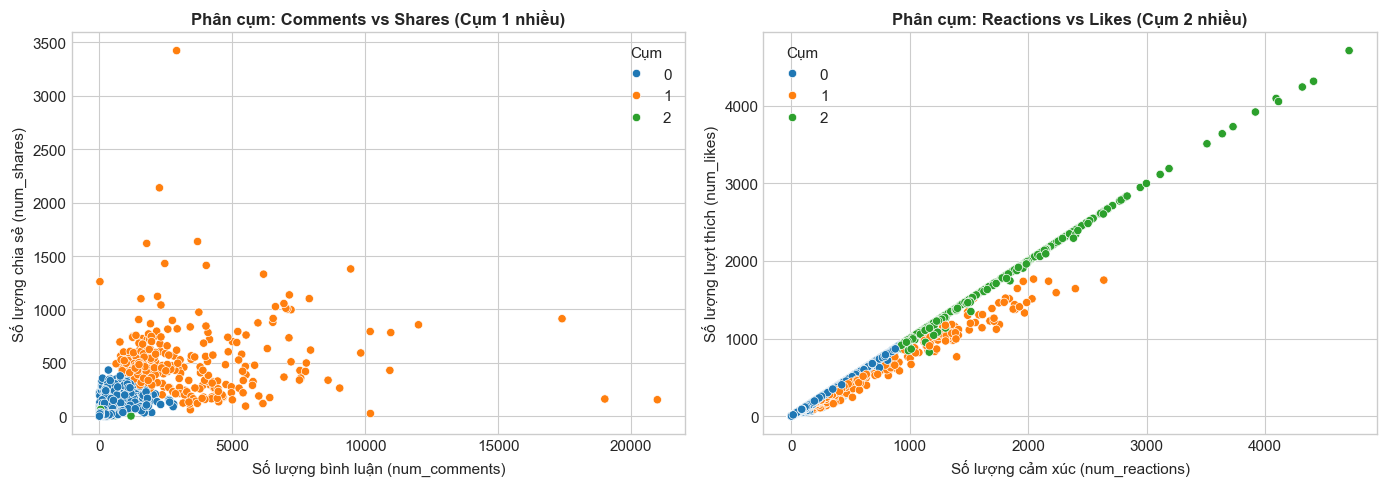

In [31]:
# F.3. Scatter plot giữa các cặp biến có độ tương quan cao
# Tạo khung gồm 1 hàng 2 cột
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: num_comments vs num_shares (Cụm 1 nhiều)
sns.scatterplot(x='num_comments', y='num_shares', hue='cluster', palette='tab10', data=df_cleaned, ax=axes[0])
axes[0].set_title('Phân cụm: Comments vs Shares (Cụm 1 nhiều)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Số lượng bình luận (num_comments)')
axes[0].set_ylabel('Số lượng chia sẻ (num_shares)')
axes[0].legend(title='Cụm')

# Biểu đồ 2: num_reactions vs num_likes (Cụm 2 nhiều)
sns.scatterplot(x='num_reactions', y='num_likes', hue='cluster', palette='tab10', data=df_cleaned, ax=axes[1])
axes[1].set_title('Phân cụm: Reactions vs Likes (Cụm 2 nhiều)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Số lượng cảm xúc (num_reactions)')
axes[1].set_ylabel('Số lượng lượt thích (num_likes)')
axes[1].legend(title='Cụm')

plt.tight_layout()
plt.show()

### 2. Định dạng Bài đăng của từng Cụm trước và sau khi Facebook Live ra mắt

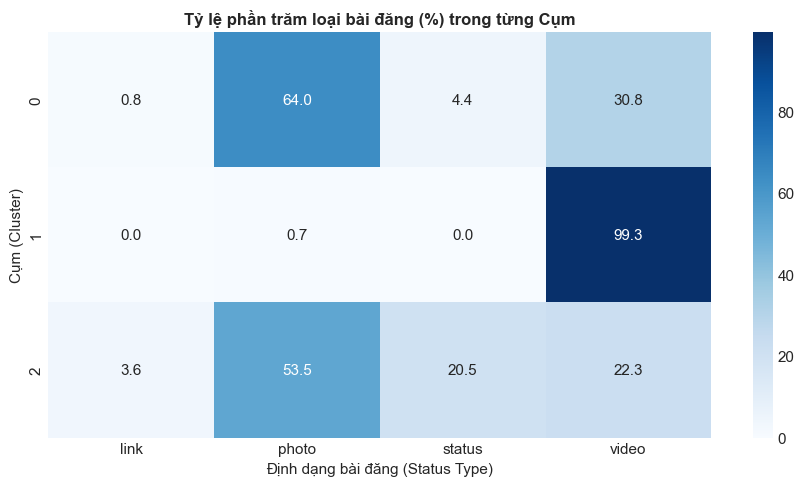

In [32]:
# F.4. Phân bố loại bài đăng (status_type) trong từng Cụm
type_crosstab = pd.crosstab(df_cleaned['cluster'], df_cleaned['status_type'], normalize='index') * 100

plt.figure(figsize=(9, 5))
sns.heatmap(type_crosstab, annot=True, fmt='.1f', cmap='Blues', cbar=True)
plt.title('Tỷ lệ phần trăm loại bài đăng (%) trong từng Cụm', fontsize=12, fontweight='bold')
plt.xlabel('Định dạng bài đăng (Status Type)')
plt.ylabel('Cụm (Cluster)')
plt.tight_layout()
plt.show()


In [33]:
# Mốc thời gian ra mắt Facebook Live toàn cầu
fb_live_launch = pd.to_datetime('2016-04-06')

# Tạo cột phân loại giai đoạn
df_cleaned['period'] = np.where(
    df_cleaned['status_published'] < fb_live_launch, 
    'Pre-Live', 
    'Post-Live'
)

# Kiểm tra phân bổ số lượng bài đăng giữa 2 giai đoạn
print(df_cleaned['period'].value_counts())

period
Post-Live    5183
Pre-Live     1813
Name: count, dtype: int64


In [34]:
# Bảng tổng hợp số lượng (Count) và phần trăm (%)
summary_table = pd.crosstab(
    [df_cleaned['cluster'], df_cleaned['period']],
    df_cleaned['status_type'],
    margins=True,
    margins_name='Tổng cộng'
)

# Bảng phần trăm theo hàng
summary_pct = (pd.crosstab(
    [df_cleaned['cluster'], df_cleaned['period']],
    df_cleaned['status_type'],
    normalize='index'
) * 100).round(2)

print("--- Tỷ lệ (%) loại bài đăng theo Cụm và Giai đoạn ---")
display(summary_pct)

--- Tỷ lệ (%) loại bài đăng theo Cụm và Giai đoạn ---


status_type        link  photo  status  video
cluster period                               
0       Post-Live  0.87  60.10    4.99  34.05
        Pre-Live   0.47  76.47    2.68  20.38
1       Post-Live  0.00   0.66    0.00  99.34
2       Post-Live  0.00  64.06   20.31  15.62
        Pre-Live   4.36  51.40   20.56  23.68

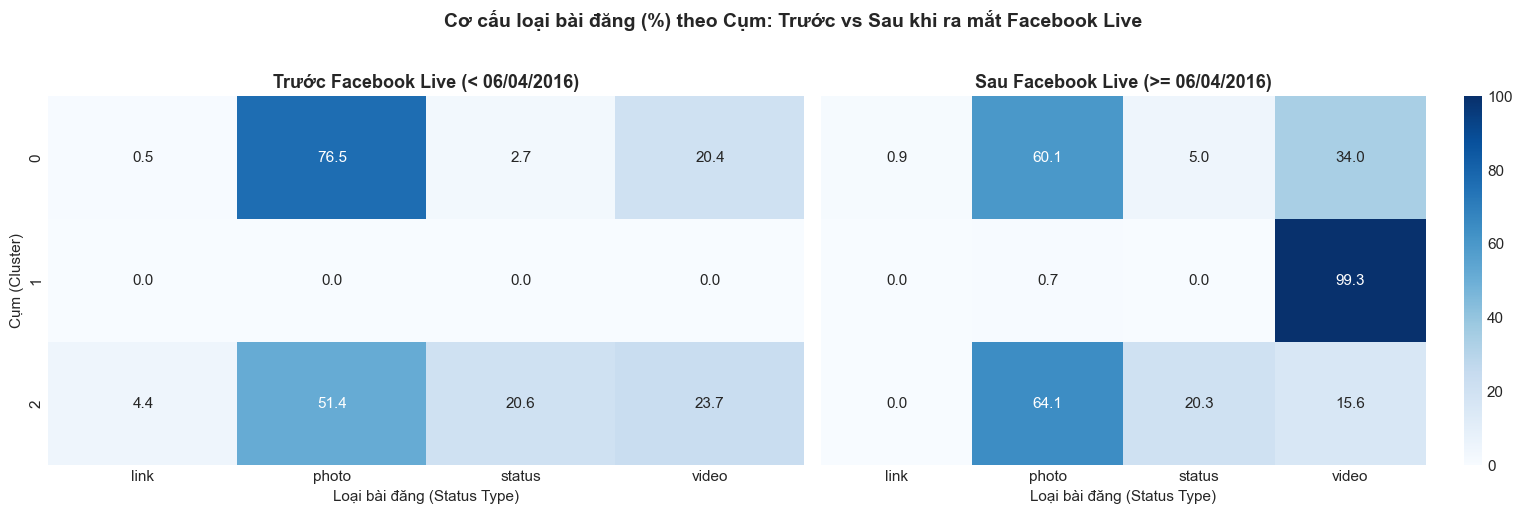

In [35]:
# F.5. Phân bố loại bài đăng (status_type) trong từng Cụm trước và sau khi có Facebook Live
# Danh sách đầy đủ tất cả các Cụm và Định dạng bài đăng
all_clusters = sorted(df_cleaned['cluster'].unique())   # [0, 1, 2]
all_types = sorted(df_cleaned['status_type'].unique()) # ['link', 'photo', 'status', 'video']

# Tính bảng crosstab tỷ lệ phần trăm theo từng dòng cho từng giai đoạn
ct_before = pd.crosstab(
    df_cleaned[df_cleaned['period'] == 'Pre-Live']['cluster'],
    df_cleaned[df_cleaned['period'] == 'Pre-Live']['status_type'],
    normalize='index'
) * 100

ct_after = pd.crosstab(
    df_cleaned[df_cleaned['period'] == 'Post-Live']['cluster'],
    df_cleaned[df_cleaned['period'] == 'Post-Live']['status_type'],
    normalize='index'
) * 100

# Đồng bộ cả dòng (index) và cột (columns)
ct_before = ct_before.reindex(index=all_clusters, columns=all_types, fill_value=0)
ct_after = ct_after.reindex(index=all_clusters, columns=all_types, fill_value=0)

# Vẽ 2 Heatmap song song
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

# Heatmap Trước 06/04/2016
sns.heatmap(ct_before, annot=True, fmt='.1f', cmap='Blues', cbar=False, ax=axes[0], vmin=0, vmax=100)
axes[0].set_title('Trước Facebook Live (< 06/04/2016)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Loại bài đăng (Status Type)')
axes[0].set_ylabel('Cụm (Cluster)')

# Heatmap Sau 06/04/2016
sns.heatmap(ct_after, annot=True, fmt='.1f', cmap='Blues', cbar=True, ax=axes[1], vmin=0, vmax=100)
axes[1].set_title('Sau Facebook Live (>= 06/04/2016)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Loại bài đăng (Status Type)')
axes[1].set_ylabel('')

plt.suptitle('Cơ cấu loại bài đăng (%) theo Cụm: Trước vs Sau khi ra mắt Facebook Live', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Nhận xét:

**Cụm 1 (Viral / High Engagement) tập trung ở giai đoạn trùng thời điểm Facebook ra mắt Live toàn cầu 06/04/2016**

1. **Trước 06/04/2016:**
   - Hầu như toàn bộ bài đăng thuộc về định dạng `photo` và phân bổ ở Cụm 0 (tương tác cơ bản) và Cụm 2 (chủ yếu là Likes).
   - Định dạng `video` xuất hiện rất ít và là dạng deferred video (video tải lên sẵn), không tạo được sự bùng nổ về bình luận hay chia sẻ.
2. **Sau 06/04/2016:**
   - **Tỷ lệ `video` tăng vọt**, đặc biệt chiếm tỷ trọng áp đảo ở **Cụm 1 (Viral)**.
   - Lý do có thể là tính năng Live bán hàng trực tiếp thúc đẩy người dùng comment chốt đơn và share livestream để nhận quà/khuyến mãi trong thời gian thực, biến `video` thành công cụ tăng trưởng tương tác mạnh nhất.

## G. Kết luận & Đề xuất Hành động

Dựa trên kết quả phân tích phân cụm:

| Tên Cụm | Đặc trưng Tương tác | Định dạng chủ đạo | Đề xuất Hành động |
| :--- | :--- | :--- | :--- |
| **Cụm 0: Standard / Low Engagement** | Tương tác mức cơ bản, ít comment và share | `photo` (Chiếm đa số) | Nhóm bài đăng duy trì nhận diện thông thường. Cần bổ sung Call-To-Action (CTA) để kích thích bình luận. |
| **Cụm 1: Viral / High Engagement** | Lượt comments và shares cực cao (trung bình **3282,78** lượt comments và **507,37** lượt shares) | `video` / `live` chiếm tỷ trọng lớn | **Nội dung chủ lực tăng chuyển đổi**. Nhà bán hàng nên đầu tư chất lượng kịch bản Livestream và Video để viral. |
| **Cụm 2: Medium Engagement** | Lượt likes và reactions cao nhưng comments/shares ở mức vừa | `photo` & `video` | Phù hợp cho các bài thông báo khuyến mãi lớn, minigame hoặc giới thiệu bộ sưu tập ảnh sản phẩm. |
